# 07 Spatiotemporal Comparison

**Objective:** compare neighbourhood-level LISA results across the complete years 2022-2025: which High-High and Low-Low clusters persisted, emerged or disappeared, and which neighbourhoods changed between cluster and outlier status.

**Main classification:** Benjamini-Hochberg FDR 5% (from notebook 06). A neighbourhood absent from a year's clusters may be (a) analysed but not significant, or (b) not analysed (island, fewer than 5 listings, no listings). These are kept apart, because a change in cluster status does not by itself show that prices changed.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd

pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 200)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROCESSED = PROJECT_ROOT / "data" / "raw", PROJECT_ROOT / "data" / "processed"
TAB, MAPS = PROJECT_ROOT / "outputs" / "tables", PROJECT_ROOT / "maps"
YEARS, MIN_LISTINGS = [2022, 2023, 2024, 2025], 5

lisa = pd.read_parquet(PROCESSED / "lisa_results.parquet")
nty = pd.read_parquet(PROCESSED / "nta_year_medians.parquet")
nta = gpd.read_file(RAW / "nta2020.geojson")
res = pd.DataFrame(nta.loc[nta["ntatype"] == "0", ["nta2020", "ntaname", "boroname"]]).reset_index(drop=True)
print("Residential NTAs:", len(res), "| LISA rows:", len(lisa), "| NTA-year medians:", len(nty))

ABBR = {"High-High": "HH", "Low-Low": "LL", "High-Low": "HL", "Low-High": "LH", "Not significant": "ns",
        "Island (excluded)": "isl", "Too few listings": "few", "No listings": "none"}

lab = lisa.set_index(["nta2020", "year"])["cluster_fdr"]
info = nty.set_index(["nta2020", "year"])

def status(code, year):
    k = (code, year)
    if k in lab.index:
        return ABBR[lab[k]]
    if k in info.index:
        return "isl" if info.loc[k, "n_listings"] >= MIN_LISTINGS else "few"
    return "none"

for y in YEARS:
    res[y] = [status(c, y) for c in res["nta2020"]]

order = ["HH", "LL", "HL", "LH", "ns", "isl", "few", "none"]
counts = pd.DataFrame({y: res[y].value_counts() for y in YEARS}).reindex(order).fillna(0).astype(int)
counts.loc["Total"] = counts.sum()
print(counts.to_string())

res.to_csv(TAB / "07_cluster_status_by_year.csv", index=False)

Residential NTAs: 197 | LISA rows: 457 | NTA-year medians: 730
       2022  2023  2024  2025
HH       14    14    13     7
LL        2     3     4     4
HL        0     0     0     0
LH        0     0     0     1
ns      108   102   103    82
isl       5     4     5     4
few      59    61    63    72
none      9    13     9    27
Total   197   197   197   197


In [2]:
res["pattern"] = res[YEARS].astype(str).agg("-".join, axis=1)
interesting = res[res[YEARS].isin(["HH", "LL", "HL", "LH"]).any(axis=1)]
print("NTAs that were a cluster or outlier in at least one year:", len(interesting))
print(interesting.sort_values(["boroname", "ntaname"])[["ntaname", "boroname", "pattern"]].to_string(index=False))

print("\nTransition 2022 -> 2025 (rows = 2022 status, columns = 2025 status):")
print(pd.crosstab(res[2022], res[2025]).reindex(index=order, columns=order).fillna(0).astype(int).to_string())

NTAs that were a cluster or outlier in at least one year: 21
                                    ntaname  boroname       pattern
  University Heights (South)-Morris Heights     Bronx  ns-LL-LL-few
                              Cypress Hills  Brooklyn   ns-LL-ns-ns
        Downtown Brooklyn-DUMBO-Boerum Hill  Brooklyn   HH-ns-ns-ns
                       Chelsea-Hudson Yards Manhattan   HH-HH-HH-HH
                      Chinatown-Two Bridges Manhattan   HH-HH-HH-LH
                    East Midtown-Turtle Bay Manhattan   HH-HH-HH-ns
                               East Village Manhattan   ns-HH-ns-ns
                                   Gramercy Manhattan   HH-HH-HH-HH
                          Greenwich Village Manhattan   HH-HH-HH-HH
                             Hell's Kitchen Manhattan   HH-HH-HH-ns
        Midtown South-Flatiron-Union Square Manhattan   HH-HH-HH-HH
                       Midtown-Times Square Manhattan   HH-HH-HH-HH
                       Murray Hill-Kips Bay Manhattan  

## 2. Why did some High-High neighbourhoods lose their status in 2025?
For neighbourhoods that were High-High in earlier years but not significant (or Low-High) in 2025, we compare their median rate, rank among analysed NTAs and number of listings in 2022 and 2025, and show their 2025 LISA quadrant and pseudo p-value (the FDR cut-off for 2025 was about 0.005). This separates a fall in rate from a loss of statistical evidence.

In [3]:
focus = ["East Midtown-Turtle Bay", "Hell's Kitchen", "SoHo-Little Italy-Hudson Square",
         "Upper East Side-Carnegie Hill", "Upper East Side-Lenox Hill-Roosevelt Island",
         "Downtown Brooklyn-DUMBO-Boerum Hill", "Chinatown-Two Bridges"]

a22 = lisa[lisa["year"] == 2022].set_index("nta2020")
a25 = lisa[lisa["year"] == 2025].set_index("nta2020")
a22["rank_pct"] = a22["median_rate"].rank(pct=True) * 100       # percentile rank among analysed NTAs that year
a25["rank_pct"] = a25["median_rate"].rank(pct=True) * 100

rows = []
for nm in focus:
    code = res.loc[res["ntaname"] == nm, "nta2020"].iloc[0]
    r22 = a22.loc[code] if code in a22.index else None
    r25 = a25.loc[code] if code in a25.index else None
    rows.append({"NTA": nm,
                 "rate_2022": None if r22 is None else r22["median_rate"],
                 "rate_2025": None if r25 is None else r25["median_rate"],
                 "listings_22": None if r22 is None else r22["n_listings"],
                 "listings_25": None if r25 is None else r25["n_listings"],
                 "rank_pct_22": None if r22 is None else r22["rank_pct"],
                 "rank_pct_25": None if r25 is None else r25["rank_pct"],
                 "quadrant_25": None if r25 is None else r25["quadrant"],
                 "p_25": None if r25 is None else r25["p_sim"]})
out = pd.DataFrame(rows)
out["pct_change"] = 100 * (out["rate_2025"] / out["rate_2022"] - 1)
print(out.to_string(index=False, float_format=lambda v: f"{v:.3f}" if abs(v) < 1 else f"{v:.1f}"))

print("\nMean median rate of analysed NTAs:", {y: round(lisa.loc[lisa['year'] == y, 'median_rate'].mean(), 1) for y in YEARS})
print("Analysed NTAs by borough in 2022 vs 2025:")
print(pd.crosstab(lisa["boroname"], lisa["year"]).to_string())

                                        NTA  rate_2022  rate_2025  listings_22  listings_25  rank_pct_22  rank_pct_25 quadrant_25  p_25  pct_change
                    East Midtown-Turtle Bay      284.2      273.6           37           26         99.2         93.6   High-High 0.007        -3.7
                             Hell's Kitchen      182.4      233.9          112           87         85.5         89.4   High-High 0.008        28.2
            SoHo-Little Italy-Hudson Square      182.2      304.5           45           35         84.7         96.8   High-High 0.011        67.2
              Upper East Side-Carnegie Hill      213.8      255.3           22           15         92.7         92.6   High-High 0.024        19.4
Upper East Side-Lenox Hill-Roosevelt Island      174.6      167.1           63           43         79.8         58.5   High-High 0.048        -4.4
        Downtown Brooklyn-DUMBO-Boerum Hill      174.9      205.5           19           13         80.6        

## 3. Cluster-transition categories (2022 vs 2025)
Neighbourhoods are grouped by their FDR status in 2022 and 2025. Clusters present only in 2023 or 2024 are grouped separately. Categories describe changes in statistical status, which may reflect changes in evidence or in the analysed set, not only changes in prices.

In [4]:
def category(r):
    a, b = r[2022], r[2025]
    if a == "HH" and b == "HH": return "High-High persisted"
    if a == "HH" and b == "LH": return "High-High became Low-High outlier"
    if a == "HH" and r[[2023, 2024, 2025]].eq("ns").all(): return "High-High in 2022 only"
    if a == "HH":               return "High-High lost (not significant in 2025)"
    if a == "LL" and b == "LL": return "Low-Low persisted"
    if b == "LL":               return "Low-Low emerged by 2025"
    if b in ("HH", "HL", "LH"): return "New cluster or outlier in 2025"
    if r[[2023, 2024]].isin(["HH", "LL", "HL", "LH"]).any(): return "Cluster in 2023-2024 only"
    return None

res["category"] = res.apply(category, axis=1)
cat = res.dropna(subset=["category"])
print(cat["category"].value_counts().to_string())
print()
print(cat.sort_values(["category", "ntaname"])[["category", "ntaname", "boroname", "pattern"]].to_string(index=False))
cat.to_csv(TAB / "07_cluster_transition_categories.csv", index=False)

category
High-High persisted                         7
High-High lost (not significant in 2025)    5
Cluster in 2023-2024 only                   3
Low-Low persisted                           2
Low-Low emerged by 2025                     2
High-High in 2022 only                      1
High-High became Low-High outlier           1

                                category                                     ntaname  boroname       pattern
               Cluster in 2023-2024 only                               Cypress Hills  Brooklyn   ns-LL-ns-ns
               Cluster in 2023-2024 only                                East Village Manhattan   ns-HH-ns-ns
               Cluster in 2023-2024 only   University Heights (South)-Morris Heights     Bronx  ns-LL-LL-few
       High-High became Low-High outlier                       Chinatown-Two Bridges Manhattan   HH-HH-HH-LH
                  High-High in 2022 only         Downtown Brooklyn-DUMBO-Boerum Hill  Brooklyn   HH-ns-ns-ns
High-High lost

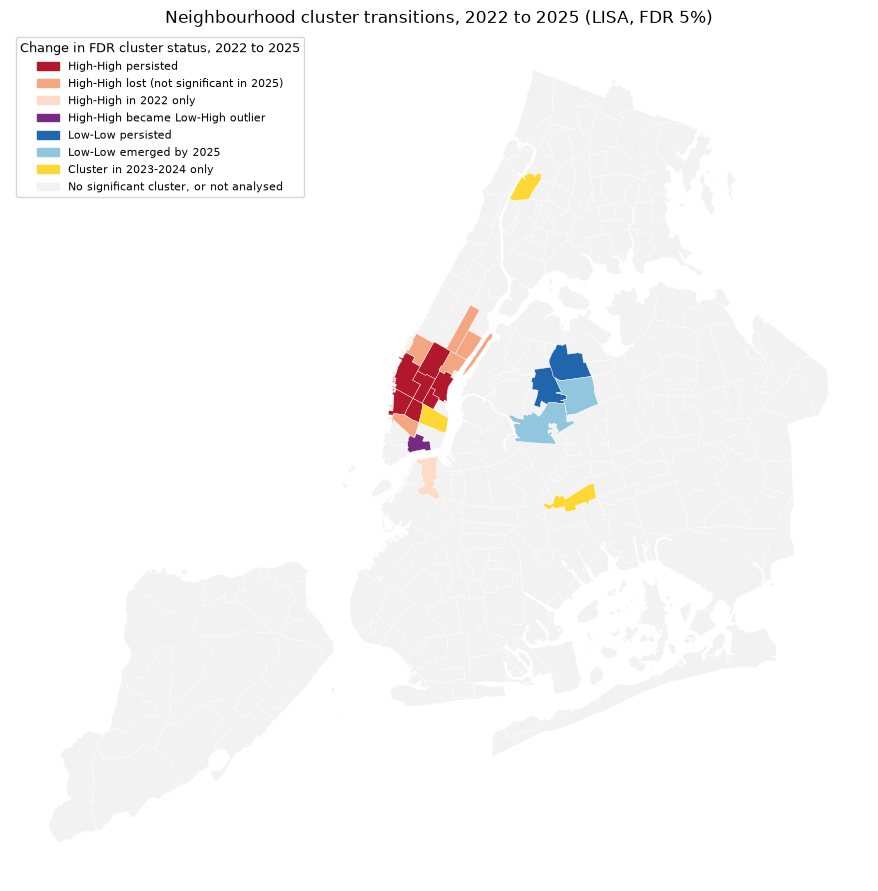

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

CAT_COLORS = {"High-High persisted": "#B2182B",
              "High-High lost (not significant in 2025)": "#F4A582",
              "High-High in 2022 only": "#FDDBC7",
              "High-High became Low-High outlier": "#762A83",
              "Low-Low persisted": "#2166AC",
              "Low-Low emerged by 2025": "#92C5DE",
              "Cluster in 2023-2024 only": "#FDD835"}

g = nta.merge(res[["nta2020", "category"]], on="nta2020", how="left").to_crs(2263)
fig, ax = plt.subplots(figsize=(9, 9))
g.plot(ax=ax, color="#F2F2F2", edgecolor="white", linewidth=0.3)
for name, c in CAT_COLORS.items():
    sub = g[g["category"] == name]
    if len(sub):
        sub.plot(ax=ax, color=c, edgecolor="white", linewidth=0.3)
ax.legend(handles=[Patch(color=c, label=n) for n, c in CAT_COLORS.items()] + [Patch(color="#F2F2F2", label="No significant cluster, or not analysed")],
          loc="upper left", fontsize=8, title="Change in FDR cluster status, 2022 to 2025", title_fontsize=9)
ax.set_title("Neighbourhood cluster transitions, 2022 to 2025 (LISA, FDR 5%)")
ax.set_axis_off()
plt.tight_layout()
plt.savefig(MAPS / "07_cluster_transitions_2022_2025.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary
- A status table for all 197 residential NTAs and each year separates clusters (HH, LL, LH, HL), analysed-but-not-significant (ns), islands, fewer than 5 listings, and no listings. Fewer than 5 listings or no listings: 68 NTAs in 2022 and 99 in 2025.
- FDR 5%: 21 NTAs were a cluster or outlier in at least one year. High-High in all four years: Chelsea-Hudson Yards, Gramercy, Greenwich Village, Midtown South-Flatiron-Union Square, Midtown-Times Square, Murray Hill-Kips Bay, West Village. Low-Low in all four years: Jackson Heights; Woodside in three of four.
- Five NTAs were High-High in 2022-2024 but not significant in 2025 (East Midtown-Turtle Bay, Hell's Kitchen, SoHo-Little Italy-Hudson Square, Upper East Side-Carnegie Hill, Upper East Side-Lenox Hill-Roosevelt Island); Downtown Brooklyn-DUMBO-Boerum Hill was High-High in 2022 only. In 2025 these retained a High-High quadrant with pseudo p-values 0.007 to 0.048 (FDR cut-off about 0.005), and their median rates changed by -4.4% to +67.2% between 2022 and 2025.
- Chinatown-Two Bridges moved from High-High (2022-2024) to a Low-High outlier in 2025 with a nearly unchanged median ($147.9 to $150.2), while the mean median rate of analysed NTAs rose from $126.8 to $158.3.
- Low-Low emerged for Elmhurst (2025) and Maspeth (2024-2025; first analysed in 2024). University Heights (South)-Morris Heights was Low-Low in 2023-2024 and fell below 5 listings in 2025. No new High-High cluster emerged and no outlier became a cluster.

## Limitations / observations
- Cluster status is relative to each year's analysed set; the 2025 set has far fewer Bronx (2) and Staten Island (0) neighbourhoods, which changes the average and the neighbours.
- A change in cluster status reflects a change in statistical evidence or in the analysed set, and does not by itself show that prices changed.
- Persistence over four years is not evidence of permanence; no causes were tested.